In [12]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


In [13]:
# Units: radius in kpc, mass in solar masses, velocity in km/s
G = 4.30091e-6  # kpc (km/s)^2 / solar mass


def simpson_integral(func, a, b, n): ## Integral method for getting mass from density function

    if n <= 0 or n % 2 != 0:
        raise ValueError("N must be positive, even number")

    step_size = (b-a)/n
    total_area = 0

    for interval in range(0, n, 2):
        left = a + interval*step_size
        middle = left + step_size
        right = middle+step_size

        area = step_size / 3 * (func(left) + 4 * func(middle) + func(right))
        total_area = total_area + area
    return total_area
    



def enclosed_mass(radii, density, rel_tol=1e-7): ## Calculates the enclosed mass from the density function at each radius
    radii = np.asarray(radii, dtype=float)
    masses = []

    def func(r):
        return 4 * np.pi * r**2 * density(r)

    for radius in radii:
        if radius < 0:
            raise ValueError("Radius cannot be negative")
        if radius == 0:
            masses.append(0.0)
            continue

        n=32                    
        previous = simpson_integral(func, 0, radius, n)
        converged = False
        while n < 16384:
            n *= 2
            mass = simpson_integral(func,0,radius,n)
            if abs(mass-previous) <= rel_tol * abs(mass):
                masses.append(mass)
                converged = True
                break
            previous = mass

        if not converged:
            raise RuntimeError("Simpson integration did not converge")

    return np.array(masses)
    

def rotation_curve(radii, density): ## Calculates dark matter contribution to the observed rotation curve

    radii = np.asarray(radii, dtype=float)

    masses = enclosed_mass(radii,density)
    velocities = []

    for i in range(len(radii)):
        radius = radii[i]
        mass = masses[i]

        if radius > 0:
            velocity = np.sqrt(G * mass / radius)
        else:
            velocity = 0.0

        velocities.append(velocity)

    return masses, np.array(velocities)   #Returns enclosed mass and circular velocity at each radius




In [14]:
# Allow running from either the project folder or the notebook folder.
data_path = Path("Rotmod_LTG/NGC2403_rotmod.dat")
if not data_path.exists():
    data_path = Path("Final Project") / data_path
data = np.loadtxt(data_path)

gal_rad = data[:, 0]
observed_velocity = data[:, 1]
velocity_error = data[:, 2]
gas_velocity = data[:, 3]
disk_velocity = data[:, 4]
bulge_velocity = data[:, 5]


# Burkert parameters
rho_0 = 3.2e7  # solar masses / kpc^3
r_0 = 5.84  # kpc

# NFW parameters
rho_s = 3.2e7   # solar masses / kpc^3
r_s = 5.84      # kpc

# Einasto parameters
rho_2 = 10.0e6   # solar masses / kpc^3
r_2 = 4.84      # kpc
alpha = 0.2    # dimensionless

## Parameters: core density and core radius
def burkert(r, rho_0, r_0): # Dark Matter Density Profile: Burkert Ansatz 
    r = np.asarray(r, dtype=float)
    x = r / r_0
    return rho_0 / ((1 + x) * (1 + x**2))

## Parameters: characteristic density, scale radius
def nfw(r, rho_s, r_s):  # Dark Matter Density Profile: NFW
    r = np.asarray(r, dtype=float)
    x = r / r_s
    return rho_s / (x * (1 + x)**2)

## Parameters: Density at radius where log(density) slope is -2, shape parameter
def einasto(r, rho_2, r_2, alpha):  # Dark Matter Density Profile: Einasto
    r = np.asarray(r, dtype=float)
    x = r / r_2
    return rho_2 * np.exp((-2 / alpha) * (x**alpha - 1))


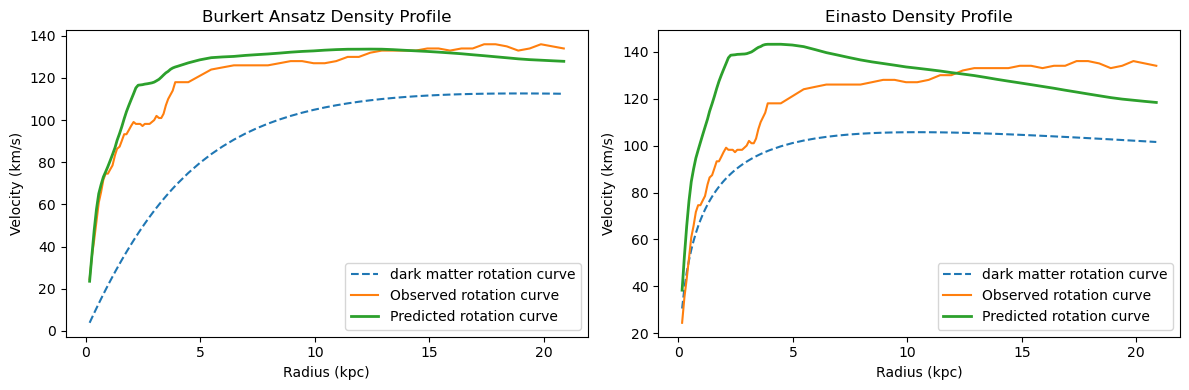

In [15]:
# Trial halo curves and visible-matter contributions.
# The unscaled SPARC stellar terms assume mass-to-light ratios of 1.
# NFW is disabled: its density diverges at the Simpson endpoint r = 0.

mass_burkert, velocity_burkert = rotation_curve(gal_rad, lambda r: burkert(r, rho_0, r_0))
# mass_nfw, velocity_nfw = rotation_curve(gal_rad, lambda r: nfw(r, rho_s, r_s))
mass_ein, velocity_ein = rotation_curve(gal_rad, lambda r: einasto(r, rho_2, r_2, alpha))


vis_velocity = np.sqrt(gas_velocity*np.abs(gas_velocity) + disk_velocity*np.abs(disk_velocity) + bulge_velocity*np.abs(bulge_velocity))


total_burkert = np.sqrt(velocity_burkert**2 + gas_velocity*np.abs(gas_velocity) + disk_velocity*np.abs(disk_velocity) + bulge_velocity*np.abs(bulge_velocity))
# total_nfw = np.sqrt(velocity_nfw**2 + gas_velocity*np.abs(gas_velocity) + disk_velocity*np.abs(disk_velocity) + bulge_velocity*np.abs(bulge_velocity))
total_ein = np.sqrt(velocity_ein**2 + gas_velocity*np.abs(gas_velocity) + disk_velocity*np.abs(disk_velocity) + bulge_velocity*np.abs(bulge_velocity))

fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(gal_rad, velocity_burkert, label='dark matter rotation curve', linestyle='--')
ax1.plot(gal_rad, observed_velocity, label='Observed rotation curve')
ax1.plot(gal_rad, total_burkert, label='Predicted rotation curve', linewidth=2)
ax1.legend()
ax1.set_title('Burkert Ansatz Density Profile')

ax3.plot(gal_rad, velocity_ein, label='dark matter rotation curve', linestyle='--')
ax3.plot(gal_rad, observed_velocity, label='Observed rotation curve')
ax3.plot(gal_rad, total_ein, label='Predicted rotation curve', linewidth=2)
ax3.legend()
ax3.set_title('Einasto Density Profile')
for axis in (ax1, ax3):
    axis.set_xlabel("Radius (kpc)")
    axis.set_ylabel("Velocity (km/s)")
plt.tight_layout()
plt.show()


In [16]:
def burkert_enclosed_mass(radius, central_density, core_radius): # Analytical equation for Burkert Profile 
    if radius == 0:
        return 0.0

    x = radius / core_radius

    log1 = np.log1p(x)
    log2 = 0.5 * np.log1p(x**2)
    bracket = log1 + log2 - np.arctan(x)
    mass = 2 * np.pi * central_density * core_radius**3 * bracket
    return mass

def burkert_model(radii, parameters): # Gives predicted velocities using Burkert Ansatz Model
    central_density = parameters[0]
    core_radius = parameters[1]
    predicted_velocities = []

    for i in range(len(radii)):
        radius = radii[i]

        if radius < 0:
            return None
        if radius == 0:
            halo_velocity_squared = 0.0
        else:
            enclosed_mass = burkert_enclosed_mass(radius, central_density, core_radius)
            halo_velocity_squared = G * enclosed_mass / radius
        gas_part = gas_velocity[i]*abs(gas_velocity[i])
        disk_part = disk_velocity[i] * abs(disk_velocity[i])
        bulge_part = bulge_velocity[i] * abs(bulge_velocity[i])
        total_velocity_squared = (
            halo_velocity_squared + gas_part + disk_part + bulge_part)

        if not np.isfinite(total_velocity_squared):
            return None
        if total_velocity_squared < 0:
            return None

        predicted_velocity = np.sqrt(total_velocity_squared)
        predicted_velocities.append(predicted_velocity)

    return np.array(predicted_velocities)


# Priors and Posteriors
def log_prior(parameters, lower_bounds, upper_bounds):
    for i in range(len(parameters)):
        value = parameters[i]
        if not np.isfinite(value):
            return -np.inf
        if value < lower_bounds[i] or value > upper_bounds[i]:
            return -np.inf
    return 0.0

def log_posterior(parameters, lower_bounds, upper_bounds):
    prior_score = log_prior(parameters, lower_bounds, upper_bounds)
    if not np.isfinite(prior_score):
        return -np.inf

    predicted_velocities = burkert_model(gal_rad, parameters)
    if predicted_velocities is None:
        return -np.inf

    chi_squared = 0.0
    for i in range(len(gal_rad)):
        residual = observed_velocity[i] - predicted_velocities[i]
        scaled_residual = residual / velocity_error[i]
        chi_squared = chi_squared + scaled_residual**2

    if not np.isfinite(chi_squared):
        return -np.inf

    return prior_score - 0.5 * chi_squared

def burkert_mcmc(starting_parameters, step_sizes, lower_bounds, upper_bounds, burn_in, total_steps):
    if burn_in < 0 or total_steps <= burn_in:
        raise ValueError("Require 0 <= burn_in < total_steps")

    current_parameters = np.array(starting_parameters, dtype=float)
    current_score = log_posterior(current_parameters, lower_bounds, upper_bounds)
    if not np.isfinite(current_score):
        raise ValueError("Starting parameters must have a finite log posterior")

    samples = []
    saved_scores = []
    accepted_moves = 0

    for step in range(total_steps):
        proposed_parameters = current_parameters.copy()

        for i in range(len(proposed_parameters)):
            change = np.random.uniform(-step_sizes[i], step_sizes[i])
            proposed_parameters[i] = current_parameters[i] + change

        proposed_score = log_posterior(proposed_parameters, lower_bounds, upper_bounds)

        accepted = False
        if np.isfinite(proposed_score):
            score_difference = proposed_score - current_score

            if score_difference >= 0:
                accepted = True

            else:
                acceptance_probability = np.exp(score_difference)
                if np.random.random() < acceptance_probability:
                    accepted = True
        if accepted:
            current_parameters = proposed_parameters
            current_score = proposed_score

        if step >= burn_in:
            samples.append(current_parameters.copy())
            saved_scores.append(current_score)
            if accepted:
                accepted_moves = accepted_moves + 1

    acceptance_rate = accepted_moves / len(samples)
    return np.array(samples), np.array(saved_scores), acceptance_rate

Median rho_0: 18363341.065863017
Median r_0: 8.036964031224286


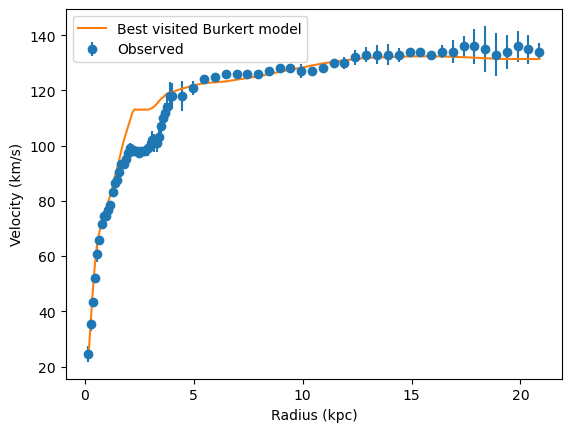

In [21]:
starting_parameters = np.array([3.2e7, 5.84])
step_sizes = np.array([2.0e6, 0.3])
lower_bounds = np.array([1.0e4, 0.1])
upper_bounds = np.array([1.0e10, 100.0])

np.random.seed(410)
samples, saved_scores, acceptance_rate = burkert_mcmc(
    starting_parameters, step_sizes, lower_bounds, upper_bounds,
    burn_in=1000, total_steps=6000
)

# Look for the highest-scoring *saved* point, without rerunning the model.
best_i = 0
for i in range(1, len(saved_scores)):
    if saved_scores[i] > saved_scores[best_i]:
        best_i = i

best_parameters = samples[best_i]
best_velocity = burkert_model(gal_rad, best_parameters)
best_chi_squared = -2 * saved_scores[best_i]
degrees_of_freedom = len(gal_rad) - 2


print("Median rho_0:", np.median(samples[:, 0]))
print("Median r_0:", np.median(samples[:, 1]))



figure, ax = plt.subplots()
ax.errorbar(gal_rad, observed_velocity, yerr=velocity_error, fmt="o", label="Observed")
ax.plot(gal_rad, best_velocity, label="Best visited Burkert model")
ax.set_xlabel("Radius (kpc)")
ax.set_ylabel("Velocity (km/s)")
ax.legend()
plt.show()